# DILIPredictor Pipeline
**Improved Detection of Drug-Induced Liver Injury by Integrating Predicted In Vivo and In Vitro Data**
*Seal et al., Chemical Research in Toxicology 2024*

This notebook faithfully reproduces Figure 1's 8-step workflow:
1. Feature selection on proxy-DILI dataset  
2. Train 9 individual proxy-DILI models (Random Forest)  
3. Scaffold-based train/test split of DILI dataset (888/223)  
4. Apply same feature selection to DILI dataset  
5. Train 5 DILI model variants (fingerprints / descriptors / combined / FeatureNet / ALL)  
6. Evaluate on held-out test set (223 compounds)  
7. Select best model  
8. Retrain on full 1,111-compound gold standard dataset  

> **Note:** Cmax (PK) features excluded — Smith et al. dataset not available locally. Only 9 proxy-DILI labels used.

## Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import time
import pickle
warnings.filterwarnings('ignore')

from rdkit import Chem
from rdkit.Chem import AllChem, MACCSkeys, Descriptors, rdMolDescriptors
from mordred import Calculator, descriptors as mordred_desc_module

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import (
    StratifiedKFold, RandomizedSearchCV, cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, matthews_corrcoef,
    f1_score, precision_score, recall_score, average_precision_score,
    roc_curve, precision_recall_curve, confusion_matrix, jaccard_score
)
import shap

np.random.seed(42)
print('All imports successful!')

All imports successful!


In [2]:
# ─── Paths ────────────────────────────────────────────────────────────────────
DATA_DIR  = '/Users/yaminichitikela/Desktop/qsar casepase/liver/'
CACHE_DIR = DATA_DIR + 'cache/'
os.makedirs(CACHE_DIR, exist_ok=True)

PROXY_PATH  = DATA_DIR + 'proxy-DILI_dataset_12133.csv'
GOLD_PATH   = DATA_DIR + 'DILI_Goldstandard_1111.csv'
TRAIN_PATH  = DATA_DIR + 'test_data_ncv_DILIst_888.csv'
TEST_PATH   = DATA_DIR + 'test_data_heldouttest_DILIst_223.csv'

# ─── Proxy-DILI endpoint mapping (9 endpoints from Table 1) ───────────────────
SOURCE_MAP = {
    ' human hepatotoxicity, hepatobiallry, literatyure and drug bank, Mulliner et al 2016':
        'human_hepatotox',
    'rats, chronic oral administration, Hepatic histopathologic effects, ToxRefDB, Liu et al':
        'animal_hepatotox_A',
    'hepatocellular hypertrophy, rats, ORAD, HESS, Ambe et al':
        'animal_hepatotox_B',
    'Preclinical hepatotoxicity data from PharmaPendium, Leadscopre, and internal repository'
    ' with 14- to 28-day rat study data, Mulliner et al 2016':
        'preclinical_hepatotox',
    'large-scale and diverse DILI dataset, Shuaibing et al':
        'diverse_DILI_A',
    'transient liver function abnormalities, adverse hepatic effects, U.S. FDA Orange Book,'
    ' Micromedex, Mora et al, Liew et al, (transient and asymptomatic liver function'
    ' abnormalities, liver function abnormalities, hyperbilirubinaemia, hepatitis, jaundice,'
    ' cholestasis, fulminant hepatitis, liver failure, and fatality)':
        'diverse_DILI_C',
    'BESP Bile Salt Export Pump Inhibition':
        'BSEP',
    'Mitotox Ecker et al':
        'mitotoxicity',
    'Reactive Metabolite Mazzolari et al':
        'reactive_metabolite',
}

ENDPOINTS = list(SOURCE_MAP.values())   # 9 endpoint names
print(f'9 proxy-DILI endpoints: {ENDPOINTS}')

9 proxy-DILI endpoints: ['human_hepatotox', 'animal_hepatotox_A', 'animal_hepatotox_B', 'preclinical_hepatotox', 'diverse_DILI_A', 'diverse_DILI_C', 'BSEP', 'mitotoxicity', 'reactive_metabolite']


## Helper Functions

In [3]:
def mol_from_smi(smi):
    try:
        return Chem.MolFromSmiles(str(smi))
    except:
        return None


def compute_morgan(smiles, radius=2, nbits=2048):
    """Morgan fingerprints → DataFrame with columns Mfp0..Mfp{nbits-1}."""
    rows = []
    for smi in smiles:
        mol = mol_from_smi(smi)
        if mol:
            fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits)
            rows.append(list(fp))
        else:
            rows.append([0] * nbits)
    return pd.DataFrame(rows, columns=[f'Mfp{i}' for i in range(nbits)])


def compute_maccs(smiles):
    """MACCS keys → DataFrame with columns MACCS0..MACCS166."""
    rows = []
    for smi in smiles:
        mol = mol_from_smi(smi)
        if mol:
            rows.append(list(MACCSkeys.GenMACCSKeys(mol)))
        else:
            rows.append([0] * 167)
    return pd.DataFrame(rows, columns=[f'MACCS{i}' for i in range(167)])


def compute_physico(smiles):
    """15 RDKit physicochemical parameters (same names as 888 file)."""
    records = []
    _zero = {k: 0 for k in ['PSA','n_rot_bonds','n_rings','n_ar_rings','n_HBA',
                             'n_HBD','Fsp3','logP','NHOHCount','NOCount',
                             'NumHeteroatoms','n_positive','_n_negative',
                             'n_ring_asmbl','n_stereo']}
    for smi in smiles:
        mol = mol_from_smi(smi)
        if mol is None:
            records.append(_zero.copy())
            continue
        try:
            ri = mol.GetRingInfo()
            records.append({
                'PSA':            rdMolDescriptors.CalcTPSA(mol),
                'n_rot_bonds':    rdMolDescriptors.CalcNumRotatableBonds(mol),
                'n_rings':        rdMolDescriptors.CalcNumRings(mol),
                'n_ar_rings':     rdMolDescriptors.CalcNumAromaticRings(mol),
                'n_HBA':          rdMolDescriptors.CalcNumHBA(mol),
                'n_HBD':          rdMolDescriptors.CalcNumHBD(mol),
                'Fsp3':           rdMolDescriptors.CalcFractionCSP3(mol),
                'logP':           Descriptors.MolLogP(mol),
                'NHOHCount':      rdMolDescriptors.CalcNumNHOH(mol),
                'NOCount':        rdMolDescriptors.CalcNumNO(mol),
                'NumHeteroatoms': rdMolDescriptors.CalcNumHeteroatoms(mol),
                'n_positive':     sum(1 for a in mol.GetAtoms() if a.GetFormalCharge() > 0),
                '_n_negative':    sum(1 for a in mol.GetAtoms() if a.GetFormalCharge() < 0),
                'n_ring_asmbl':   len(ri.AtomRings()),
                'n_stereo':       rdMolDescriptors.CalcNumStereocenters(mol),
            })
        except:
            records.append(_zero.copy())
    return pd.DataFrame(records)


def compute_mordred(smiles, keep_cols=None, cache_path=None):
    """
    Compute Mordred 2D descriptors. Caches to disk after first run.
    keep_cols: if given, restrict output to these column names (for alignment).
    """
    if cache_path and os.path.exists(cache_path):
        print(f'  Loading cached Mordred from {os.path.basename(cache_path)}')
        df = pd.read_csv(cache_path, index_col=0)
        if keep_cols is not None:
            df = df[[c for c in keep_cols if c in df.columns]]
        return df

    print(f'  Computing Mordred for {len(smiles)} compounds (may take ~10-15 min)...')
    t0 = time.time()
    calc = Calculator(mordred_desc_module, ignore_3D=True)
    dummy = Chem.MolFromSmiles('C')
    mols = [mol_from_smi(s) or dummy for s in smiles]
    df = calc.pandas(mols)
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna(axis=1)                          # drop any descriptor with NaN
    print(f'  Done in {time.time()-t0:.0f}s — {df.shape[1]} valid descriptors.')
    if cache_path:
        df.to_csv(cache_path)
    if keep_cols is not None:
        df = df[[c for c in keep_cols if c in df.columns]]
    return df


def j_threshold(y_true, y_prob):
    """Optimal decision threshold from Youden's J statistic."""
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return thr[np.argmax(tpr - fpr)]


def metrics(y_true, y_pred, y_prob):
    """All evaluation metrics from the paper."""
    cm = confusion_matrix(y_true, y_pred)
    if cm.size < 4:
        return {}
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0
    spec = tn / (tn + fp) if (tn + fp) else 0
    lr_p = sens / (1 - spec) if spec < 1 else np.inf
    return {
        'AUC-ROC': round(roc_auc_score(y_true, y_prob), 3),
        'AUC-PR':  round(average_precision_score(y_true, y_prob), 3),
        'BA':      round(balanced_accuracy_score(y_true, y_pred), 3),
        'MCC':     round(matthews_corrcoef(y_true, y_pred), 3),
        'F1':      round(f1_score(y_true, y_pred, zero_division=0), 3),
        'Sens':    round(sens, 3),
        'Spec':    round(spec, 3),
        'LR+':     round(lr_p, 3),
        'PPV':     round(precision_score(y_true, y_pred, zero_division=0), 3),
    }

print('Helper functions ready.')

Helper functions ready.


---
## STEP 1 — Feature Selection on Proxy-DILI Dataset
Variance threshold filters:
- Morgan FP (2048 bits): threshold **0.05** → target ~89 bits  
- MACCS keys (167 bits): threshold **0.10** → target ~100 keys  
- Mordred descriptors: threshold **0.10** → target ~653 descriptors  
- Physicochemical (15 params): always kept

In [4]:
proxy_df = pd.read_csv(PROXY_PATH)
proxy_df = proxy_df.reset_index(drop=True)
print(f'Proxy-DILI dataset: {proxy_df.shape[0]} compounds, {proxy_df["TOXICITY"].sum()} active')
print('\nEndpoint sizes:')
for src, ep in SOURCE_MAP.items():
    n = (proxy_df['Source'] == src).sum()
    act = proxy_df.loc[proxy_df['Source'] == src, 'TOXICITY'].sum()
    print(f'  {ep:25s}: {n:5d} compounds  ({act} active)')

Proxy-DILI dataset: 12133 compounds, 4383 active

Endpoint sizes:
  human_hepatotox          :     0 compounds  (0 active)
  animal_hepatotox_A       :   542 compounds  (184 active)
  animal_hepatotox_B       :   671 compounds  (369 active)
  preclinical_hepatotox    :  2204 compounds  (1642 active)
  diverse_DILI_A           :  1106 compounds  (382 active)
  diverse_DILI_C           :   384 compounds  (199 active)
  BSEP                     :   446 compounds  (240 active)
  mitotoxicity             :  5239 compounds  (689 active)
  reactive_metabolite      :   317 compounds  (81 active)


In [5]:
# ─── Identify Mordred columns available in the pre-computed 888 file ──────────
# We restrict proxy-DILI Mordred computation to the same columns so features
# align perfectly between proxy-DILI models and the DILI train/test datasets.
train_ref = pd.read_csv(TRAIN_PATH, nrows=0)  # just headers
PHYSICO_COLS = ['PSA','n_rot_bonds','n_rings','n_ar_rings','n_HBA','n_HBD',
                'Fsp3','logP','NHOHCount','NOCount','NumHeteroatoms',
                'n_positive','_n_negative','n_ring_asmbl','n_stereo']
# All non-fingerprint, non-physico columns in the 888 file = Mordred descriptors
DILI_MORDRED_COLS = [
    c for c in train_ref.columns
    if c not in ['smiles_r','TOXICITY','Source_rank','Source','Data',
                 'InChIKey','InChIKey14','protonated_smiles_r']
    and not c.startswith('Mfp')
    and not c.startswith('MACCS')
    and c not in PHYSICO_COLS
]
print(f'Mordred columns in 888 file: {len(DILI_MORDRED_COLS)}')
print(f'Physicochemical columns: {len(PHYSICO_COLS)}')

Mordred columns in 888 file: 1001
Physicochemical columns: 15


In [6]:
proxy_smiles = proxy_df['smiles_r'].values

# Morgan fingerprints (~30s)
print('Computing Morgan fingerprints...')
t0 = time.time()
proxy_morgan = compute_morgan(proxy_smiles)
print(f'  Done in {time.time()-t0:.1f}s  shape={proxy_morgan.shape}')

# MACCS keys (~15s)
print('Computing MACCS keys...')
t0 = time.time()
proxy_maccs = compute_maccs(proxy_smiles)
print(f'  Done in {time.time()-t0:.1f}s  shape={proxy_maccs.shape}')

# Physicochemical parameters (~30s)
print('Computing physicochemical parameters...')
t0 = time.time()
proxy_physico = compute_physico(proxy_smiles)
print(f'  Done in {time.time()-t0:.1f}s  shape={proxy_physico.shape}')

# Mordred descriptors — cached; only keep columns present in 888 file for alignment
print('Computing Mordred descriptors (cached after first run)...')
proxy_mordred = compute_mordred(
    proxy_smiles,
    keep_cols=DILI_MORDRED_COLS,
    cache_path=CACHE_DIR + 'proxy_mordred_aligned.csv'
)
print(f'  Aligned Mordred shape: {proxy_mordred.shape}')

Computing Morgan fingerprints...


[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerator
[15:07:29] DEPRECATION WARNING: please use MorganGenerat

  Done in 22.8s  shape=(12133, 2048)
Computing MACCS keys...


[15:07:52] Explicit valence for atom # 29 P, 6, is greater than permitted
[15:07:52] Explicit valence for atom # 16 P, 6, is greater than permitted
[15:07:52] Explicit valence for atom # 26 P, 6, is greater than permitted
[15:07:52] Explicit valence for atom # 1 P, 6, is greater than permitted
[15:07:52] Explicit valence for atom # 37 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 28 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 8 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 26 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 20 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 42 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 14 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 23 P, 6, is greater than permitted
[15:07:53] Explicit valence for atom # 11 P, 7, is greater than permitted
[15:07:53] Explicit valence for atom # 1

  Done in 21.4s  shape=(12133, 167)
Computing physicochemical parameters...


[15:08:13] Explicit valence for atom # 29 P, 6, is greater than permitted
[15:08:13] Explicit valence for atom # 16 P, 6, is greater than permitted
[15:08:13] Explicit valence for atom # 26 P, 6, is greater than permitted
[15:08:13] Explicit valence for atom # 1 P, 6, is greater than permitted
[15:08:13] Explicit valence for atom # 37 P, 6, is greater than permitted
[15:08:13] Explicit valence for atom # 28 P, 6, is greater than permitted
[15:08:13] Explicit valence for atom # 8 P, 6, is greater than permitted
[15:08:14] Explicit valence for atom # 26 P, 6, is greater than permitted
[15:08:14] Explicit valence for atom # 20 P, 6, is greater than permitted
[15:08:14] Explicit valence for atom # 42 P, 6, is greater than permitted
[15:08:14] Explicit valence for atom # 14 P, 6, is greater than permitted
[15:08:14] Explicit valence for atom # 23 P, 6, is greater than permitted
[15:08:14] Explicit valence for atom # 11 P, 7, is greater than permitted
[15:08:14] Explicit valence for atom # 1

... (21 outputs left out)

 51%|█████     | 6136/12133 [06:37<21:11,  4.72it/s]  

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


100%|██████████| 12133/12133 [10:31<00:00, 19.22it/s] 


  Done in 637s — 1002 valid descriptors.
  Aligned Mordred shape: (12133, 999)


In [7]:
# ─── Variance threshold feature selection ─────────────────────────────────────
vt_morgan = VarianceThreshold(threshold=0.05)
vt_morgan.fit(proxy_morgan.values)
SEL_MORGAN = proxy_morgan.columns[vt_morgan.get_support()].tolist()

vt_maccs = VarianceThreshold(threshold=0.10)
vt_maccs.fit(proxy_maccs.values)
SEL_MACCS = proxy_maccs.columns[vt_maccs.get_support()].tolist()

# Variance threshold on Mordred only; physico always kept
vt_mordred = VarianceThreshold(threshold=0.10)
vt_mordred.fit(proxy_mordred.values)
SEL_MORDRED = proxy_mordred.columns[vt_mordred.get_support()].tolist()

# Final feature groups
SEL_STRUCT = SEL_MORGAN + SEL_MACCS
SEL_DESC   = PHYSICO_COLS + SEL_MORDRED   # physico always included
SEL_ALL    = SEL_STRUCT + SEL_DESC

print('=== STEP 1 Feature Selection Results ===')
print(f'Morgan FP:  {proxy_morgan.shape[1]:4d} → {len(SEL_MORGAN):3d} selected  (paper target: 89)')
print(f'MACCS keys: {proxy_maccs.shape[1]:4d} → {len(SEL_MACCS):3d} selected  (paper target: 100)')
print(f'Mordred:    {proxy_mordred.shape[1]:4d} → {len(SEL_MORDRED):3d} selected  (paper target: 653)')
print(f'Physico:    {len(PHYSICO_COLS):4d} → {len(PHYSICO_COLS):3d} (always kept)')
print(f'───────────────────────────────────────')
print(f'Struct fingerprints:    {len(SEL_STRUCT):3d}  (paper: 189)')
print(f'Molecular descriptors:  {len(SEL_DESC):3d}  (paper: 668)')
print(f'Total:                  {len(SEL_ALL):3d}')

=== STEP 1 Feature Selection Results ===
Morgan FP:  2048 →  85 selected  (paper target: 89)
MACCS keys:  167 →  99 selected  (paper target: 100)
Mordred:     999 → 649 selected  (paper target: 653)
Physico:      15 →  15 (always kept)
───────────────────────────────────────
Struct fingerprints:    184  (paper: 189)
Molecular descriptors:  664  (paper: 668)
Total:                  848


In [8]:
# Assemble proxy-DILI feature matrix (selected features only)
proxy_X = pd.concat([
    proxy_morgan[SEL_MORGAN].reset_index(drop=True),
    proxy_maccs[SEL_MACCS].reset_index(drop=True),
    proxy_physico[PHYSICO_COLS].reset_index(drop=True),
    proxy_mordred[SEL_MORDRED].reset_index(drop=True),
], axis=1)
print(f'Proxy-DILI feature matrix: {proxy_X.shape}')

Proxy-DILI feature matrix: (12133, 848)


---
## STEP 2 — Train Individual Proxy-DILI Models
One Random Forest classifier per proxy-DILI endpoint.  
- 5-fold stratified CV + RandomizedSearchCV hyperparameter optimization  
- J-statistic threshold for binary decisions

In [9]:
RF_PARAM_GRID = {
    'n_estimators':     [100, 200, 500],
    'max_depth':        [None, 10, 20],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features':     ['sqrt', 'log2'],
    'class_weight':     ['balanced', None],
}

proxy_models    = {}
proxy_thresholds = {}
proxy_cv_aucs   = {}

print('STEP 2: Training 9 proxy-DILI models\n')
for src, ep in SOURCE_MAP.items():
    mask = proxy_df['Source'] == src
    X_ep = proxy_X[mask.values].reset_index(drop=True)
    y_ep = proxy_df.loc[mask, 'TOXICITY'].values
    n_pos, n_neg = int(y_ep.sum()), int((y_ep == 0).sum())

    print(f'[{ep}]  n={len(y_ep)} (pos={n_pos}, neg={n_neg})')
    if n_pos < 10 or n_neg < 10:
        print('  → Skipping: insufficient class samples\n')
        continue

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    search = RandomizedSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        RF_PARAM_GRID, n_iter=20, cv=skf,
        scoring='roc_auc', random_state=42, n_jobs=-1, verbose=0
    )
    search.fit(X_ep, y_ep)
    best = search.best_estimator_

    # J-statistic threshold from OOF predictions
    oof_probs = cross_val_predict(best, X_ep, y_ep, cv=skf, method='predict_proba')[:, 1]
    thr = j_threshold(y_ep, oof_probs)

    proxy_models[ep]     = best
    proxy_thresholds[ep] = thr
    proxy_cv_aucs[ep]    = search.best_score_
    print(f'  CV AUC={search.best_score_:.3f}  J-threshold={thr:.3f}')
    print(f'  Best params: n_est={search.best_params_["n_estimators"]}, '
          f'max_depth={search.best_params_["max_depth"]}\n')

print(f'Trained {len(proxy_models)} proxy-DILI models.')

STEP 2: Training 9 proxy-DILI models

[human_hepatotox]  n=0 (pos=0, neg=0)
  → Skipping: insufficient class samples

[animal_hepatotox_A]  n=542 (pos=184, neg=358)
  CV AUC=0.812  J-threshold=0.456
  Best params: n_est=100, max_depth=None

[animal_hepatotox_B]  n=671 (pos=369, neg=302)
  CV AUC=0.769  J-threshold=0.558
  Best params: n_est=500, max_depth=None

[preclinical_hepatotox]  n=2204 (pos=1642, neg=562)
  CV AUC=0.757  J-threshold=0.730
  Best params: n_est=500, max_depth=None

[diverse_DILI_A]  n=1106 (pos=382, neg=724)
  CV AUC=0.862  J-threshold=0.406
  Best params: n_est=500, max_depth=None

[diverse_DILI_C]  n=384 (pos=199, neg=185)
  CV AUC=0.766  J-threshold=0.491
  Best params: n_est=500, max_depth=20

[BSEP]  n=446 (pos=240, neg=206)
  CV AUC=0.868  J-threshold=0.509
  Best params: n_est=500, max_depth=None

[mitotoxicity]  n=5239 (pos=689, neg=4550)
  CV AUC=0.920  J-threshold=0.168
  Best params: n_est=500, max_depth=None

[reactive_metabolite]  n=317 (pos=81, neg=2

## Proxy-DILI Model Cross-Prediction Analysis (Figure 3 equivalent)

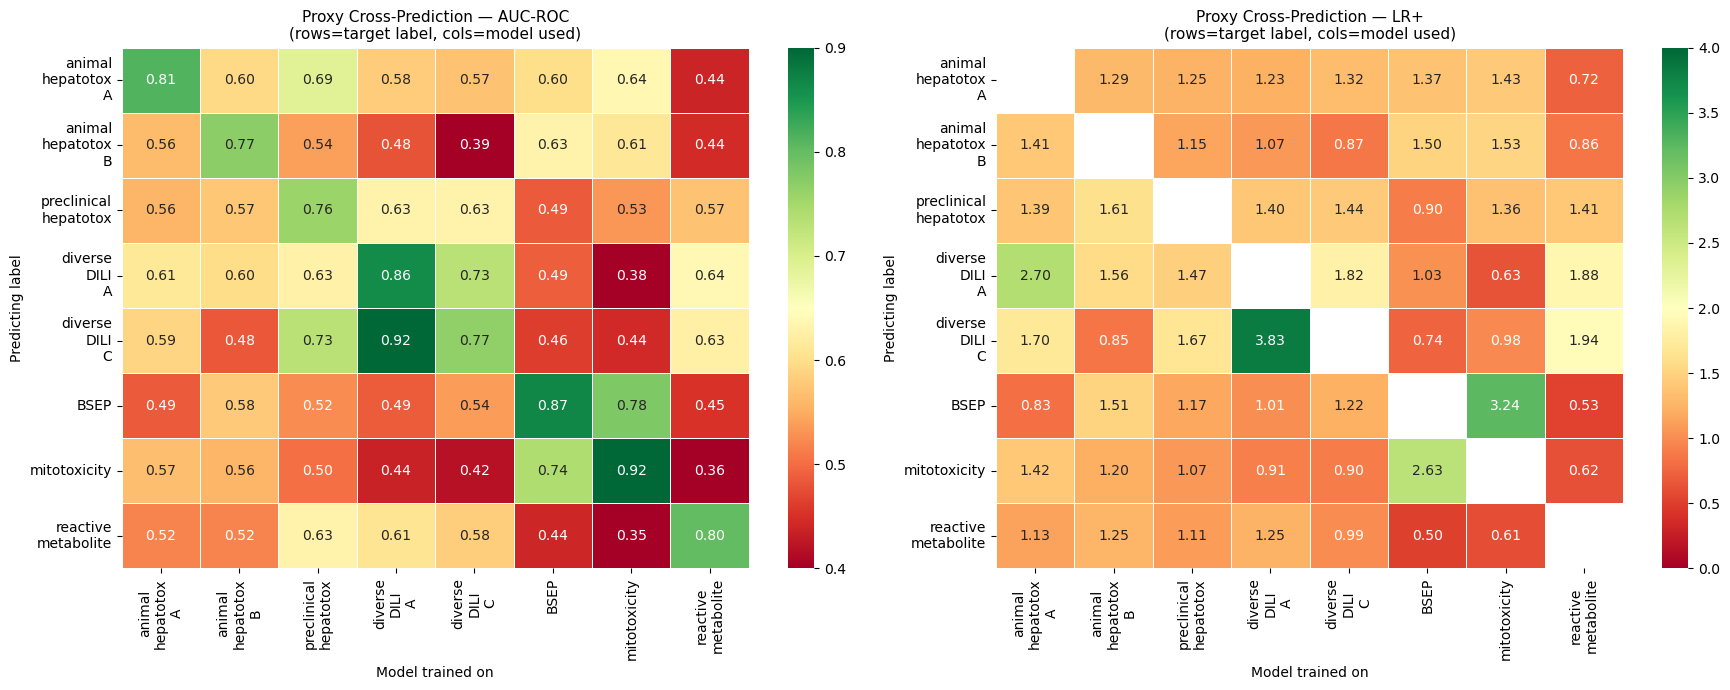

Saved figure3_proxy_cross_predictions.png


In [10]:
ep_list = list(proxy_models.keys())
n_ep    = len(ep_list)
auc_mat = np.full((n_ep, n_ep), np.nan)
lr_mat  = np.full((n_ep, n_ep), np.nan)

for i, ep_target in enumerate(ep_list):
    src_i = [s for s, e in SOURCE_MAP.items() if e == ep_target][0]
    mask_i = proxy_df['Source'] == src_i
    X_i = proxy_X[mask_i.values].reset_index(drop=True)
    y_i = proxy_df.loc[mask_i, 'TOXICITY'].values
    if len(np.unique(y_i)) < 2:
        continue
    for j, ep_model in enumerate(ep_list):
        if i == j:
            auc_mat[i, j] = proxy_cv_aucs[ep_target]
        else:
            try:
                probs = proxy_models[ep_model].predict_proba(X_i)[:, 1]
                auc_mat[i, j] = roc_auc_score(y_i, probs)
                # LR+ using J-threshold of ep_model
                preds = (probs >= proxy_thresholds[ep_model]).astype(int)
                cm = confusion_matrix(y_i, preds)
                if cm.size == 4:
                    tn, fp, fn, tp = cm.ravel()
                    sens = tp / (tp+fn) if (tp+fn) else 0
                    spec = tn / (tn+fp) if (tn+fp) else 0
                    lr_mat[i, j] = sens / (1-spec) if spec < 1 else np.inf
            except:
                pass

short = [e.replace('_', '\n') for e in ep_list]
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, mat, title, fmt in zip(
    axes,
    [auc_mat, lr_mat],
    ['AUC-ROC', 'LR+'],
    ['.2f', '.2f']
):
    sns.heatmap(mat, xticklabels=short, yticklabels=short,
                annot=True, fmt=fmt, cmap='RdYlGn',
                vmin=(0.4 if title=='AUC-ROC' else 0),
                vmax=(0.9 if title=='AUC-ROC' else 4),
                ax=ax, linewidths=0.5)
    ax.set_title(f'Proxy Cross-Prediction — {title}\n(rows=target label, cols=model used)', fontsize=11)
    ax.set_xlabel('Model trained on', fontsize=10)
    ax.set_ylabel('Predicting label', fontsize=10)

plt.tight_layout()
plt.savefig(DATA_DIR + 'figure3_proxy_cross_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figure3_proxy_cross_predictions.png')

---
## STEP 3 — Load Pre-Split DILI Dataset
Scaffold-based (Butina clustering, Tanimoto ≥ 0.70) split already applied:  
**888 training** / **223 held-out test** compounds

STEP 3: DILI Dataset Split
  Training: 888 compounds  (toxic=560, non-toxic=328)
  Test:     223 compounds  (toxic=156, non-toxic=67)


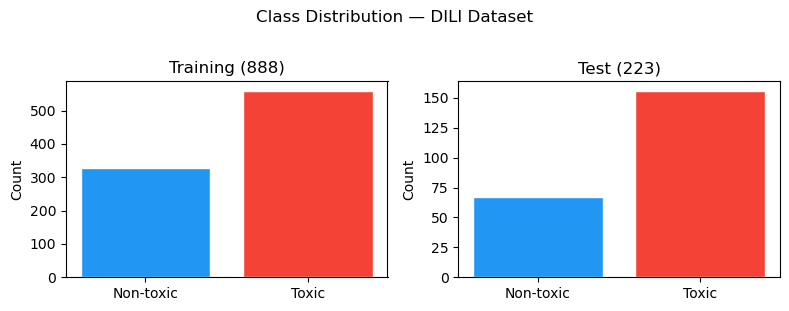

In [11]:
train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

y_train = train_df['TOXICITY'].values
y_test  = test_df['TOXICITY'].values

print('STEP 3: DILI Dataset Split')
print(f'  Training: {len(y_train)} compounds  (toxic={y_train.sum()}, non-toxic={(y_train==0).sum()})')
print(f'  Test:     {len(y_test)} compounds  (toxic={y_test.sum()}, non-toxic={(y_test==0).sum()})')

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, y, title in zip(axes, [y_train, y_test], ['Training (888)', 'Test (223)']):
    ax.bar(['Non-toxic', 'Toxic'], [(y==0).sum(), y.sum()],
           color=['#2196F3', '#F44336'], edgecolor='white')
    ax.set_title(title)
    ax.set_ylabel('Count')
plt.suptitle('Class Distribution — DILI Dataset', y=1.02)
plt.tight_layout()
plt.show()

---
## STEP 4 — Apply Same Feature Selection to DILI Dataset
Use the variance threshold column selections (SEL_MORGAN, SEL_MACCS, SEL_MORDRED)
derived from the proxy-DILI dataset — no information leakage.

In [12]:
# Match selected columns to what's available in the pre-computed 888/223 files
dili_cols = train_df.columns.tolist()

avail_morgan  = [c for c in SEL_MORGAN  if c in dili_cols]
avail_maccs   = [c for c in SEL_MACCS   if c in dili_cols]
avail_physico = [c for c in PHYSICO_COLS if c in dili_cols]
avail_mordred = [c for c in SEL_MORDRED  if c in dili_cols]

print('STEP 4: Feature column alignment (proxy-DILI selection → DILI files)')
print(f'  Morgan:  {len(SEL_MORGAN):3d} selected → {len(avail_morgan):3d} matched in DILI files')
print(f'  MACCS:   {len(SEL_MACCS):3d} selected → {len(avail_maccs):3d} matched')
print(f'  Physico: {len(PHYSICO_COLS):3d}          → {len(avail_physico):3d} matched')
print(f'  Mordred: {len(SEL_MORDRED):3d} selected → {len(avail_mordred):3d} matched')

STRUCT_COLS   = avail_morgan + avail_maccs
DESC_COLS     = avail_physico + avail_mordred
ALL_FEAT_COLS = STRUCT_COLS + DESC_COLS
print(f'\n  Structural fingerprints: {len(STRUCT_COLS)}')
print(f'  Molecular descriptors:   {len(DESC_COLS)}')
print(f'  Total:                   {len(ALL_FEAT_COLS)}')

# Extract feature matrices
X_tr_struct = train_df[STRUCT_COLS].values
X_tr_desc   = train_df[DESC_COLS].values
X_tr_sd     = train_df[ALL_FEAT_COLS].values

X_te_struct = test_df[STRUCT_COLS].values
X_te_desc   = test_df[DESC_COLS].values
X_te_sd     = test_df[ALL_FEAT_COLS].values

STEP 4: Feature column alignment (proxy-DILI selection → DILI files)
  Morgan:   85 selected →  85 matched in DILI files
  MACCS:    99 selected →  99 matched
  Physico:  15          →  15 matched
  Mordred: 649 selected → 649 matched

  Structural fingerprints: 184
  Molecular descriptors:   664
  Total:                   848


## Generate Proxy-DILI Predictions for DILI Compounds (FeatureNet Features)

In [13]:
# The proxy-DILI models were trained on SEL_ALL columns.
# We apply them to the same columns in the 888/223 DILI files.
proxy_feat_in_dili = [c for c in SEL_ALL if c in dili_cols]
print(f'Proxy-DILI model features available in DILI files: {len(proxy_feat_in_dili)}/{len(SEL_ALL)}')

proxy_tr_preds = {}   # probabilities for training set
proxy_te_preds = {}   # probabilities for test set
test_aucs_individual = {}

print('\nProxy-DILI model predictions on held-out DILI test set:')
for ep, model in proxy_models.items():
    X_tr_proxy = train_df[proxy_feat_in_dili].values
    X_te_proxy = test_df[proxy_feat_in_dili].values

    p_train = model.predict_proba(X_tr_proxy)[:, 1]
    p_test  = model.predict_proba(X_te_proxy)[:, 1]

    proxy_tr_preds[ep] = p_train
    proxy_te_preds[ep] = p_test

    thr  = proxy_thresholds[ep]
    auc  = roc_auc_score(y_test, p_test)
    ba   = balanced_accuracy_score(y_test, (p_test >= thr).astype(int))
    test_aucs_individual[ep] = auc
    print(f'  [{ep:25s}] AUC={auc:.3f}  BA={ba:.3f}')

# Stack into matrices
X_tr_proxy = np.column_stack([proxy_tr_preds[ep] for ep in proxy_models])
X_te_proxy = np.column_stack([proxy_te_preds[ep] for ep in proxy_models])
print(f'\nProxy feature matrix: train={X_tr_proxy.shape}, test={X_te_proxy.shape}')

Proxy-DILI model features available in DILI files: 848/848

Proxy-DILI model predictions on held-out DILI test set:
  [animal_hepatotox_A       ] AUC=0.559  BA=0.529
  [animal_hepatotox_B       ] AUC=0.548  BA=0.550
  [preclinical_hepatotox    ] AUC=0.600  BA=0.588
  [diverse_DILI_A           ] AUC=0.587  BA=0.556
  [diverse_DILI_C           ] AUC=0.574  BA=0.595
  [BSEP                     ] AUC=0.543  BA=0.550
  [mitotoxicity             ] AUC=0.617  BA=0.617
  [reactive_metabolite      ] AUC=0.499  BA=0.509

Proxy feature matrix: train=(888, 8), test=(223, 8)


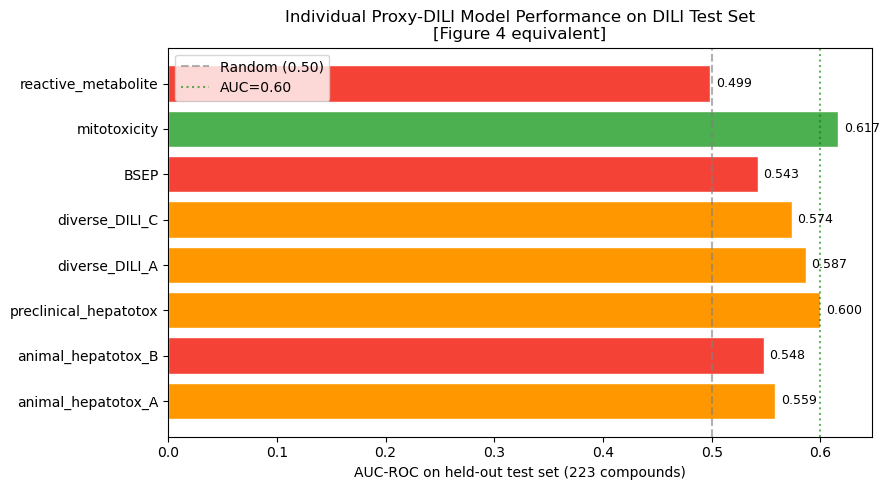

In [14]:
# Figure 4 equivalent — individual proxy-DILI model performance on DILI test set
ep_names = list(test_aucs_individual.keys())
aucs     = [test_aucs_individual[e] for e in ep_names]

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#4CAF50' if a > 0.60 else '#FF9800' if a > 0.55 else '#F44336' for a in aucs]
bars = ax.barh(ep_names, aucs, color=colors, edgecolor='white')
ax.axvline(0.50, ls='--', color='gray', alpha=0.6, label='Random (0.50)')
ax.axvline(0.60, ls=':', color='green', alpha=0.6, label='AUC=0.60')
for bar, auc in zip(bars, aucs):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{auc:.3f}', va='center', fontsize=9)
ax.set_xlabel('AUC-ROC on held-out test set (223 compounds)')
ax.set_title('Individual Proxy-DILI Model Performance on DILI Test Set\n[Figure 4 equivalent]')
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR + 'figure4_individual_proxy_performance.png', dpi=150, bbox_inches='tight')
plt.show()

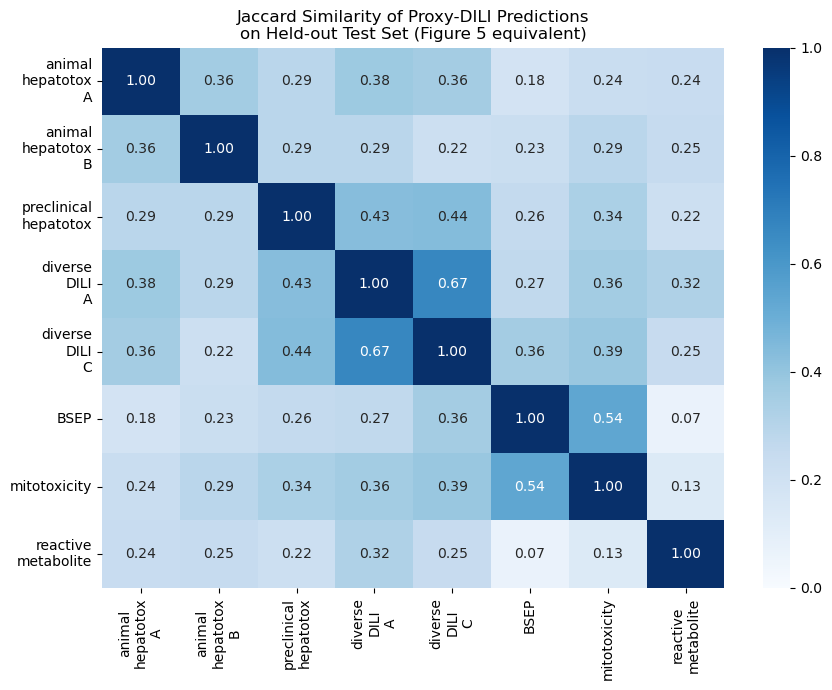

In [15]:
# Figure 5 equivalent — Jaccard similarity of proxy model predictions
pred_mat = np.column_stack([
    (proxy_te_preds[ep] >= proxy_thresholds[ep]).astype(int)
    for ep in proxy_models
])
n_ep = len(proxy_models)
jaccard_mat = np.zeros((n_ep, n_ep))
for i in range(n_ep):
    for j in range(n_ep):
        jaccard_mat[i, j] = jaccard_score(pred_mat[:, i], pred_mat[:, j],
                                          zero_division=0)

fig, ax = plt.subplots(figsize=(9, 7))
short = [e.replace('_', '\n') for e in proxy_models]
sns.heatmap(jaccard_mat, xticklabels=short, yticklabels=short,
            annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title('Jaccard Similarity of Proxy-DILI Predictions\non Held-out Test Set (Figure 5 equivalent)')
plt.tight_layout()
plt.savefig(DATA_DIR + 'figure5_jaccard_similarity.png', dpi=150, bbox_inches='tight')
plt.show()

---
## STEP 5 — Train 5 DILI Model Variants
Repeated nested cross-validation (5 outer folds × 4 inner folds, 5 repetitions).  
Best model selected by validation AUC.

| Variant | Features |
|---------|----------|
| **(a)** | Structural fingerprints only |
| **(b)** | Molecular descriptors only |
| **(c)** | Structure + Descriptors |
| **(d)** | Proxy-DILI labels only (FeatureNet) |
| **(e)** | **ALL combined → DILIPredictor** |

In [16]:
def train_dili_model(X_tr, y_tr, X_te, y_te, name,
                     n_repeats=5, n_outer=5, n_inner=4, n_iter=20):
    """
    Repeated nested CV (simplified paper procedure).
    Outer loop selects the best model; inner loop tunes hyperparameters.
    Returns: model, threshold, test_metrics, mean_val_auc
    """
    PARAMS = {
        'n_estimators':      [100, 200, 500, 1000],
        'max_depth':         [None, 10, 20, 50],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf':  [1, 2, 4],
        'max_features':      ['sqrt', 'log2'],
        'class_weight':      ['balanced', None],
    }

    best_auc = -np.inf
    best_model = None
    val_aucs = []

    for rep in range(n_repeats):
        skf = StratifiedKFold(n_splits=n_outer, shuffle=True, random_state=rep)
        for fold, (tr_idx, val_idx) in enumerate(skf.split(X_tr, y_tr)):
            X_f, X_v = X_tr[tr_idx], X_tr[val_idx]
            y_f, y_v = y_tr[tr_idx], y_tr[val_idx]

            inner_cv = StratifiedKFold(n_splits=n_inner, shuffle=True,
                                       random_state=rep * 100 + fold)
            search = RandomizedSearchCV(
                RandomForestClassifier(random_state=42, n_jobs=-1),
                PARAMS, n_iter=n_iter, cv=inner_cv,
                scoring='roc_auc', random_state=rep * 100 + fold,
                n_jobs=-1, verbose=0
            )
            search.fit(X_f, y_f)
            v_prob = search.best_estimator_.predict_proba(X_v)[:, 1]
            v_auc = roc_auc_score(y_v, v_prob) if len(np.unique(y_v)) > 1 else 0.5
            val_aucs.append(v_auc)

            if v_auc > best_auc:
                best_auc   = v_auc
                best_model = search.best_estimator_

    # Refit on full training set
    best_model.fit(X_tr, y_tr)

    # J-statistic threshold from 4-fold CV on training set
    cv4 = StratifiedKFold(n_splits=4, shuffle=True, random_state=99)
    oof  = cross_val_predict(best_model, X_tr, y_tr, cv=cv4, method='predict_proba')[:, 1]
    thr  = j_threshold(y_tr, oof)

    # Evaluate on held-out test
    te_prob = best_model.predict_proba(X_te)[:, 1]
    te_pred = (te_prob >= thr).astype(int)
    m = metrics(y_te, te_pred, te_prob)

    print(f'  [{name}]')
    print(f'    rNCV mean AUC: {np.mean(val_aucs):.3f} ± {np.std(val_aucs):.3f}')
    print(f'    J-threshold:   {thr:.3f}')
    print(f'    Test: AUC-ROC={m["AUC-ROC"]}  AUC-PR={m["AUC-PR"]}  '
          f'BA={m["BA"]}  LR+={m["LR+"]}  PPV={m["PPV"]}')
    return best_model, thr, m, float(np.mean(val_aucs))

print('STEP 5: Training 5 DILI model variants (may take ~20-40 min)...')

STEP 5: Training 5 DILI model variants (may take ~20-40 min)...


In [17]:
# Combined feature matrices
X_tr_all = np.concatenate([X_tr_struct, X_tr_desc, X_tr_proxy], axis=1)
X_te_all = np.concatenate([X_te_struct, X_te_desc, X_te_proxy], axis=1)

FEATURE_SETS = {
    'a_structural': (X_tr_struct,  X_te_struct,  'Structural fingerprints'),
    'b_descriptors':(X_tr_desc,    X_te_desc,    'Molecular descriptors'),
    'c_struct_desc':(X_tr_sd,      X_te_sd,      'Structure + Descriptors'),
    'd_featurenet': (X_tr_proxy,   X_te_proxy,   'FeatureNet (proxy-DILI)'),
    'e_combined':   (X_tr_all,     X_te_all,     'DILIPredictor (ALL)'),
}

MODELS      = {}
THRESHOLDS  = {}
RESULTS     = {}
CV_AUCS     = {}

for key, (Xtr, Xte, name) in FEATURE_SETS.items():
    mod, thr, met, cv_auc = train_dili_model(
        Xtr, y_train, Xte, y_test, name,
        n_repeats=3, n_outer=5, n_inner=4, n_iter=15
    )
    MODELS[key]     = mod
    THRESHOLDS[key] = thr
    RESULTS[key]    = met
    CV_AUCS[key]    = cv_auc

print('\nAll 5 models trained.')

  [Structural fingerprints]
    rNCV mean AUC: 0.689 ± 0.035
    J-threshold:   0.454
    Test: AUC-ROC=0.593  AUC-PR=0.776  BA=0.531  LR+=1.078  PPV=0.715
  [Molecular descriptors]
    rNCV mean AUC: 0.678 ± 0.045
    J-threshold:   0.618
    Test: AUC-ROC=0.613  AUC-PR=0.792  BA=0.56  LR+=1.323  PPV=0.755
  [Structure + Descriptors]
    rNCV mean AUC: 0.683 ± 0.044
    J-threshold:   0.591
    Test: AUC-ROC=0.626  AUC-PR=0.8  BA=0.581  LR+=1.4  PPV=0.765
  [FeatureNet (proxy-DILI)]
    rNCV mean AUC: 0.666 ± 0.043
    J-threshold:   0.632
    Test: AUC-ROC=0.652  AUC-PR=0.807  BA=0.589  LR+=1.477  PPV=0.775
  [DILIPredictor (ALL)]
    rNCV mean AUC: 0.681 ± 0.043
    J-threshold:   0.584
    Test: AUC-ROC=0.618  AUC-PR=0.786  BA=0.582  LR+=1.377  PPV=0.762

All 5 models trained.


---
## STEP 6 — Evaluate on Held-out Test Set (223 compounds)  
## STEP 7 — Compare Models & Select Best (Table 2)

In [18]:
MODEL_LABELS = {
    'a_structural':  'Chemical structure only (Morgan + MACCS)',
    'b_descriptors': 'Physicochemical properties (Mordred)',
    'c_struct_desc': 'Structure + Physicochemical',
    'd_featurenet':  'Proxy-DILI labels only (FeatureNet)',
    'e_combined':    'DILIPredictor (ALL combined)',
}

rows = []
for key, label in MODEL_LABELS.items():
    m = RESULTS[key]
    rows.append({'Model': label, **m})

table2 = pd.DataFrame(rows).set_index('Model')
print('\nTable 2 — Performance on Held-out Test Set (223 compounds)')
print('Paper reference: DILIPredictor AUC-ROC=0.63, AUC-PR=0.79, LR+=1.40 (with Cmax)\n')
print(table2.to_string())
table2.to_csv(DATA_DIR + 'table2_model_comparison.csv')
print('\nSaved table2_model_comparison.csv')


Table 2 — Performance on Held-out Test Set (223 compounds)
Paper reference: DILIPredictor AUC-ROC=0.63, AUC-PR=0.79, LR+=1.40 (with Cmax)

                                          AUC-ROC  AUC-PR     BA    MCC     F1   Sens   Spec    LR+    PPV
Model                                                                                                     
Chemical structure only (Morgan + MACCS)    0.593   0.776  0.531  0.076  0.778  0.853  0.209  1.078  0.715
Physicochemical properties (Mordred)        0.613   0.792  0.560  0.111  0.597  0.494  0.627  1.323  0.755
Structure + Physicochemical                 0.626   0.800  0.581  0.148  0.649  0.564  0.597  1.400  0.765
Proxy-DILI labels only (FeatureNet)         0.652   0.807  0.589  0.163  0.644  0.551  0.627  1.477  0.775
DILIPredictor (ALL combined)                0.618   0.786  0.582  0.150  0.669  0.596  0.567  1.377  0.762

Saved table2_model_comparison.csv


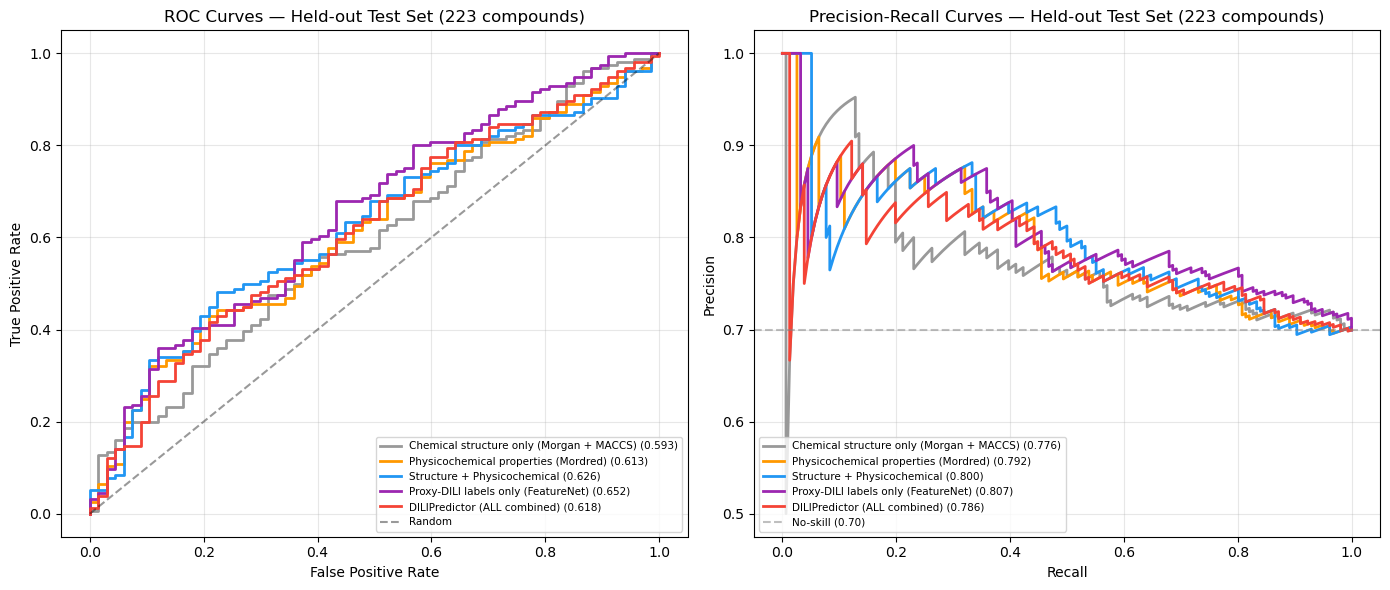

In [19]:
# ROC and Precision-Recall curves
X_TE_MAP = {
    'a_structural':  X_te_struct,
    'b_descriptors': X_te_desc,
    'c_struct_desc': X_te_sd,
    'd_featurenet':  X_te_proxy,
    'e_combined':    X_te_all,
}
COLORS = {
    'a_structural':  '#999999',
    'b_descriptors': '#FF9800',
    'c_struct_desc': '#2196F3',
    'd_featurenet':  '#9C27B0',
    'e_combined':    '#F44336',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for key, model in MODELS.items():
    probs = model.predict_proba(X_TE_MAP[key])[:, 1]
    label = MODEL_LABELS[key]

    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_roc = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, color=COLORS[key], lw=2,
                 label=f'{label} ({auc_roc:.3f})')

    prec, rec, _ = precision_recall_curve(y_test, probs)
    auc_pr = average_precision_score(y_test, probs)
    axes[1].plot(rec, prec, color=COLORS[key], lw=2,
                 label=f'{label} ({auc_pr:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate',
            title='ROC Curves — Held-out Test Set (223 compounds)')
axes[0].legend(loc='lower right', fontsize=7.5)
axes[0].grid(alpha=0.3)

baseline = y_test.mean()
axes[1].axhline(baseline, ls='--', color='gray', alpha=0.5,
                label=f'No-skill ({baseline:.2f})')
axes[1].set(xlabel='Recall', ylabel='Precision',
            title='Precision-Recall Curves — Held-out Test Set (223 compounds)')
axes[1].legend(loc='lower left', fontsize=7.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(DATA_DIR + 'figure6_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# LR+ at low false-positive rate (top-N detection, paper Figure 7 concept)
print('LR+ at progressive FPR thresholds (top-N true positive detection):')
print(f'{"Model":<42}  LR+@5%FPR  LR+@10%FPR  LR+@20%FPR')

for key, model in MODELS.items():
    probs = model.predict_proba(X_TE_MAP[key])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    interp = np.interp
    lr5  = interp(0.05, fpr, tpr) / 0.05  if interp(0.05,  fpr, tpr) > 0 else 0
    lr10 = interp(0.10, fpr, tpr) / 0.10  if interp(0.10,  fpr, tpr) > 0 else 0
    lr20 = interp(0.20, fpr, tpr) / 0.20  if interp(0.20,  fpr, tpr) > 0 else 0
    print(f'{MODEL_LABELS[key]:<42}  {lr5:7.2f}   {lr10:8.2f}   {lr20:8.2f}')

LR+ at progressive FPR thresholds (top-N true positive detection):
Model                                       LR+@5%FPR  LR+@10%FPR  LR+@20%FPR
Chemical structure only (Morgan + MACCS)       3.21       1.99       1.60
Physicochemical properties (Mordred)           2.18       2.50       2.02
Structure + Physicochemical                    1.67       2.69       2.15
Proxy-DILI labels only (FeatureNet)            2.82       2.56       2.02
DILIPredictor (ALL combined)                   2.82       1.99       1.89
